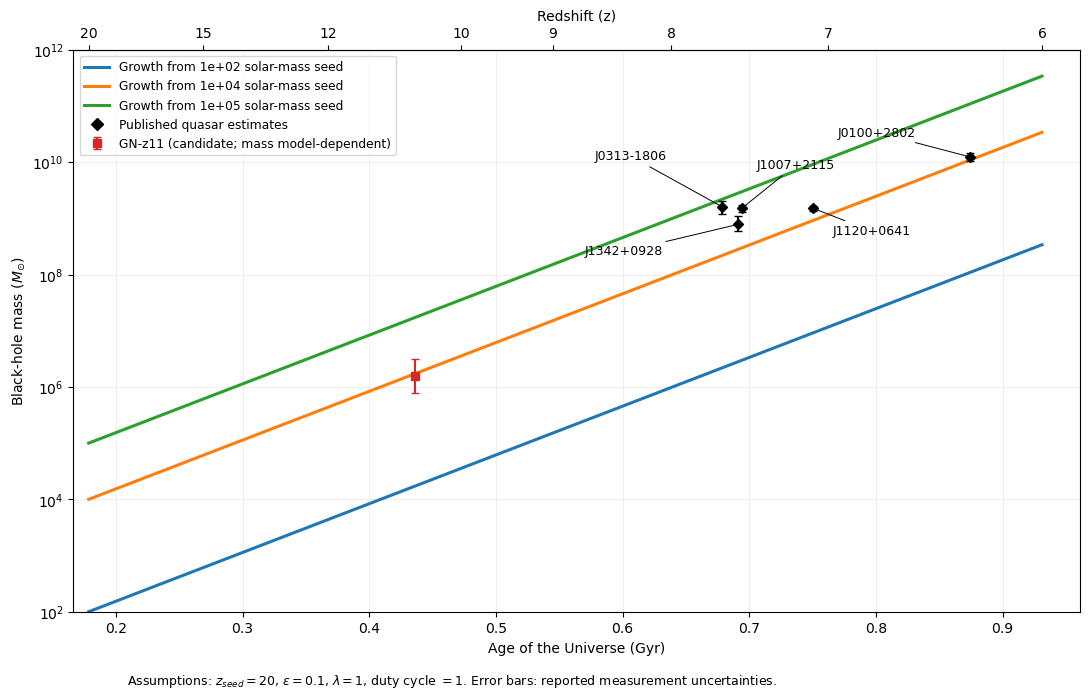

PDF saved to: /mnt/zfs/jupyter-p03/home/bdelgiud/AUTO_DELETE/2026-02-17
Eddington timescale: 0.4505 Gyr
E-folding time: 50.05 Myr

Predicted black-hole masses:

J0313-1806, z=7.642
Observed mass: 1.600e+09 Msun
Seed 1e+02 Msun: 2.191e+06 Msun
Seed 1e+04 Msun: 2.191e+08 Msun
Seed 1e+05 Msun: 2.191e+09 Msun
Required seed mass: 7.304e+04 Msun

J1342+0928, z=7.54
Observed mass: 7.800e+08 Msun
Seed 1e+02 Msun: 2.796e+06 Msun
Seed 1e+04 Msun: 2.796e+08 Msun
Seed 1e+05 Msun: 2.796e+09 Msun
Required seed mass: 2.790e+04 Msun

J1007+2115, z=7.515
Observed mass: 1.500e+09 Msun
Seed 1e+02 Msun: 2.971e+06 Msun
Seed 1e+04 Msun: 2.971e+08 Msun
Seed 1e+05 Msun: 2.971e+09 Msun
Required seed mass: 5.048e+04 Msun

J1120+0641, z=7.085
Observed mass: 1.520e+09 Msun
Seed 1e+02 Msun: 9.121e+06 Msun
Seed 1e+04 Msun: 9.121e+08 Msun
Seed 1e+05 Msun: 9.121e+09 Msun
Required seed mass: 1.666e+04 Msun

J0100+2802, z=6.3
Observed mass: 1.240e+10 Msun
Seed 1e+02 Msun: 1.092e+08 Msun
Seed 1e+04 Msun: 1.092e+10 Msun


In [1]:

# PHYS 474 - Black Hole Growth vs Observed Quasars

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.constants import G, c, m_p, parsec, physical_constants

# Save files in the current Jupyter directory
OUTPUT = Path.cwd()

# 1. Model parameters
Z_SEED = 20.0
EPSILON = 0.10
EDDINGTON_RATIO = 1.0
DUTY_CYCLE = 1.0
SEED_MASSES = [1e2, 1e4, 1e5]

# 2. Cosmological parameters (Planck18-like)
H0 = 67.66
OMEGA_M = 0.30966
OMEGA_R = 9.1e-5
OMEGA_L = 1 - OMEGA_M - OMEGA_R

H0_SI = H0 * 1000 / (parsec * 1e6)
SEC_PER_GYR = 1e9 * 365.25 * 24 * 3600
SIGMA_T = physical_constants['Thomson cross section'][0]

try:
    from astropy.cosmology import Planck18
except ImportError:
    Planck18 = None


# 3. Convert redshift to cosmic age
def age_gyr(z):
    if Planck18 is not None:
        return float(Planck18.age(z).value)

    def integrand(zz):
        zp1 = 1 + zz
        E = np.sqrt(
            OMEGA_R * zp1**4 +
            OMEGA_M * zp1**3 +
            OMEGA_L
        )
        return 1 / (zp1 * E)

    return quad(integrand, z, np.inf)[0] / H0_SI / SEC_PER_GYR


# 4. Calculate Eddington growth timescale
T_EDD = (
    c * SIGMA_T / (4 * np.pi * G * m_p)
) / SEC_PER_GYR

T_GROWTH = (
    T_EDD * EPSILON /
    ((1 - EPSILON) * EDDINGTON_RATIO * DUTY_CYCLE)
)


# 5. Published high-redshift quasars
# Format: name, redshift, mass, lower error, upper error
# All masses are in solar masses
quasars = [
    ('J0313-1806', 7.642, 1.60e9, 0.40e9, 0.40e9),
    ('J1342+0928', 7.540, 7.80e8, 1.90e8, 3.30e8),
    ('J1007+2115', 7.515, 1.50e9, 0.20e9, 0.20e9),
    ('J1120+0641', 7.085, 1.52e9, 0.17e9, 0.17e9),
    ('J0100+2802', 6.300, 1.24e10, 0.19e10, 0.19e10)
]


# 6. Calculate theoretical growth curves
z_grid = np.linspace(Z_SEED, 6.0, 650)

t_grid = np.array([
    age_gyr(float(z)) for z in z_grid
])

t_seed = age_gyr(Z_SEED)

fig, ax = plt.subplots(figsize=(11, 7))

for seed_mass in SEED_MASSES:

    # Exponential black-hole growth equation
    masses = seed_mass * np.exp(
        (t_grid - t_seed) / T_GROWTH
    )

    ax.plot(
        t_grid,
        masses,
        linewidth=2.2,
        label=f'Growth from {seed_mass:.0e} solar-mass seed'
    )


# 7. Add observed quasar masses
for name, z, mass, err_minus, err_plus in quasars:

    ax.errorbar(
        age_gyr(z),
        mass,
        yerr=[[err_minus], [err_plus]],
        fmt='D',
        markersize=5,
        capsize=3,
        color='black',
        zorder=5
    )

ax.plot(
    [], [],
    'D',
    color='black',
    label='Published quasar estimates'
)


# 8. Add GN-z11 as a separate candidate
# Maiolino et al. (2024):
# log10(M/Msun) = 6.2 +/- 0.3

mass_gn = 10**6.2

ax.errorbar(
    age_gyr(10.6),
    mass_gn,
    yerr=[
        [mass_gn - 10**5.9],
        [10**6.5 - mass_gn]
    ],
    fmt='s',
    markersize=6,
    capsize=3,
    label='GN-z11 (candidate; mass model-dependent)'
)


# 9. Label observed quasars
label_offsets = {
    'J0313-1806': (-92, 34),
    'J1342+0928': (-110, -22),
    'J1007+2115': (11, 29),
    'J1120+0641': (14, -19),
    'J0100+2802': (-95, 15)
}

for name, z, mass, _, _ in quasars:

    ax.annotate(
        name,
        (age_gyr(z), mass),
        xytext=label_offsets[name],
        textcoords='offset points',
        fontsize=9,
        arrowprops={
            'arrowstyle': '-',
            'lw': 0.7
        }
    )


# 10. Format the graph
ax.set_xlabel('Age of the Universe (Gyr)')
ax.set_ylabel(r'Black-hole mass ($M_{\odot}$)')

ax.set_xlim(
    t_seed - 0.012,
    age_gyr(6.0) + 0.03
)

ax.set_ylim(1e2, 1e12)
ax.set_yscale('log')

ax.grid(True, which='both', alpha=0.18)
ax.legend(fontsize=8.8, loc='upper left')


# 11. Add redshift labels on the upper x-axis
z_ticks = [20, 15, 12, 10, 9, 8, 7, 6]

ax_top = ax.secondary_xaxis('top')

ax_top.set_xticks(
    [age_gyr(z) for z in z_ticks],
    labels=[str(z) for z in z_ticks]
)

ax_top.set_xlabel('Redshift (z)')


# 12. Add model assumptions
fig.text(
    0.12,
    0.015,
    r'Assumptions: $z_{seed}=20$, '
    r'$\epsilon=0.1$, $\lambda=1$, duty cycle $=1$.'
    ' Error bars: reported measurement uncertainties.',
    fontsize=9
)

fig.tight_layout(rect=(0, 0.035, 1, 1))


# 13. Save figure
fig.savefig(
    OUTPUT / 'figure1_growth_vs_observations.png',
    dpi=220,
    bbox_inches='tight'
)

fig.savefig(
    OUTPUT / 'figure1_growth_vs_observations.pdf',
    bbox_inches='tight'
)

plt.show()

OUTPUT = Path.cwd()

fig.savefig(
    OUTPUT / "preliminary_black_hole_growth.pdf",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("PDF saved to:", OUTPUT)

# 14. Print model results
print(f'Eddington timescale: {T_EDD:.4f} Gyr')
print(f'E-folding time: {T_GROWTH * 1000:.2f} Myr')

print("\nPredicted black-hole masses:")

for name, z, observed_mass, _, _ in quasars:

    delta_t = age_gyr(z) - t_seed

    print(f"\n{name}, z={z}")
    print(f"Observed mass: {observed_mass:.3e} Msun")

    for seed_mass in SEED_MASSES:

        predicted_mass = seed_mass * np.exp(
            delta_t / T_GROWTH
        )

        print(
            f"Seed {seed_mass:.0e} Msun: "
            f"{predicted_mass:.3e} Msun"
        )

    # Calculate required seed mass
    required_seed = observed_mass * np.exp(
        -delta_t / T_GROWTH
    )

    print(f"Required seed mass: {required_seed:.3e} Msun")

print("\nFiles saved in:", OUTPUT)
